# 4.3.6. ML5 - Privacy-Utility Trade-off

RetailRocket: dự đoán mua hàng theo session, DP-SGD gộp gradient theo khách hàng.
Notebook có kết quả đã chạy. Trong VS Code, chọn **Select Kernel** rồi chạy các ô
theo thứ tự. Đổi `RUN_TRAINING = True` ở ô cấu hình nếu cần huấn luyện lại.

**Phạm vi riêng tư:** ε là accounting của cơ chế huấn luyện theo người với roster
công khai cố định. Cả pipeline và gói kết quả chưa được chứng nhận user-level DP.
Đọc phần cuối trước khi viết kết luận về bảo vệ dữ liệu.


## Chuẩn bị môi trường

Cài extension Python và Jupyter của Microsoft. Nếu thiếu thư viện, bỏ dấu `#` ở
ô dưới rồi chạy và chọn lại kernel khi cần. Các file `.csv.gz` được đọc trực tiếp.


In [1]:
# %pip install -r requirements_ml5.txt


In [2]:
from pathlib import Path
import sys
import subprocess
import pandas as pd
from IPython.display import Image, Markdown

BASE = Path.cwd()
if not (BASE / 'run_ml5_privacy.py').exists() and (BASE / 'outputs').exists():
    BASE = BASE / 'outputs'
required = ['run_ml5_privacy.py', 'test_ml5_privacy.py',
            'ml4_train.csv.gz', 'ml4_val.csv.gz', 'ml4_test.csv.gz']
missing = [name for name in required if not (BASE / name).exists()]
assert not missing, f'Thiếu file: {missing}. Mở đúng thư mục outputs.'
print('Thư mục làm việc:', BASE)
print('Python kernel:', sys.executable)


Thư mục làm việc: C:\Users\84969\Documents\Codex\2026-10-12\referenced-chatgpt-conversation-this-is-an\outputs
Python kernel: C:\Program Files\Python313\python.exe


## 4.3.6.1. DP-SGD

Một người dùng là một `visitorid`. Loss của người đó là trung bình weighted BCE
trên toàn bộ phiên train. Gộp gradient trước, cắt norm chung weight/bias tại C=100,
thêm Gaussian vào tổng gradient rồi chia số người kỳ vọng của batch. Opacus xử lý
clipping/noise và RDP accounting. Lấy mẫu Poisson theo người, không theo phiên.

Các caps của đặc trưng và purchase weight 100 cố định, không fit trên dữ liệu.
Centralized và federated có baseline không DP chạy lại cùng loss/tiền xử lý ML5.


In [3]:
RUN_TRAINING = False  # Đổi True để chạy lại; False để xem kết quả có sẵn.
RESULTS = BASE / 'ml5_results'
EPSILON_TARGETS = [1, 3, 5, 8]
REPLICATES = 3
EPOCHS = 3
ROUNDS = 6
LOCAL_EPOCHS = 1
CLIP_NORM = 100
DELTA = 1e-7


In [4]:
if RUN_TRAINING:
    check = subprocess.run([sys.executable, str(BASE / 'test_ml5_privacy.py')],
                           cwd=BASE, text=True, capture_output=True)
    print(check.stdout + check.stderr)
    check.check_returncode()
    command = [sys.executable, '-u', str(BASE / 'run_ml5_privacy.py'),
               '--data-dir', str(BASE), '--output-dir', str(RESULTS),
               '--epsilon-targets', *map(str, EPSILON_TARGETS),
               '--replicates', str(REPLICATES), '--epochs', str(EPOCHS),
               '--rounds', str(ROUNDS), '--local-epochs', str(LOCAL_EPOCHS),
               '--clip', str(CLIP_NORM), '--delta', str(DELTA)]
    process = subprocess.Popen(command, cwd=BASE, stdout=subprocess.PIPE,
                               stderr=subprocess.STDOUT, text=True, encoding='utf-8')
    for line in process.stdout:
        print(line, end='')
    if process.wait() != 0:
        raise RuntimeError('Huấn luyện bị lỗi. Đọc dòng lỗi phía trên.')
else:
    print('Đang đọc kết quả đã chạy. RUN_TRAINING=True để huấn luyện lại.')
assert (RESULTS / 'ml5_results_summary.csv').exists(), 'Chưa có kết quả. Hãy chạy huấn luyện.'


Đang đọc kết quả đã chạy. RUN_TRAINING=True để huấn luyện lại.


In [5]:
import json
summary = json.loads((RESULTS / 'ml5_experiment_summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{
    'Train sessions': summary['train_sessions'], 'Train users': summary['train_users'],
    'Validation sessions': summary['val_sessions'], 'Test sessions': summary['test_sessions'],
    'Clients': summary['num_clients'], 'Runs / configuration': summary['replicates']
}]))
print('Đơn vị privacy:', summary['privacy_unit'])
print('Randomness:', summary['randomness_mode'])
report = (RESULTS / 'ML5_Privacy_Utility_Report.md').read_text(encoding='utf-8')

def report_section(number):
    body = report.split(f'## 4.3.6.{number}.', 1)[1].split('## 4.3.6.', 1)[0]
    lines = body.splitlines(keepends=True)[1:]
    return ''.join(line for line in lines if not line.startswith('!['))

display(Markdown(report_section(1)))


,Train sessions,Train users,Validation sessions,Test sessions,Clients,Runs / configuration
0,1408588,1133850,176074,176074,50,3



Dùng lại dữ liệu session đã chuẩn bị cho ML4: 1,408,588 phiên train,
176,074 phiên validation và 176,074 phiên test.
Nhãn là `label_has_purchase`, bảy đặc trưng chỉ sử dụng phần quan sát trước giao dịch.
Đơn vị lấy mẫu và cắt gradient là một `visitorid`, gồm toàn bộ phiên TRAIN của người đó.
Tổng số người trong train là 1,133,850. Một khách hàng thuộc đúng một client.

Với khách hàng u, loss là trung bình weighted BCE trên các phiên của u, với trọng số
purchase cố định 100. Gradient của tất cả phiên được
gộp thành một gradient người dùng trước khi cắt chung weight và bias tại C =
100. Opacus DPOptimizer thêm Gaussian với độ lệch chuẩn σC
vào TỔNG gradient rồi chia cho số người kỳ vọng của batch. Lấy mẫu Poisson độc lập
theo người; batch rỗng vẫn thêm nhiễu và được accountant ghi nhận.

Mô hình Logistic Regression khởi tạo từ 0. Biến đổi đặc trưng dùng các chặn miền cố
định và log1p, không fit scaler hay tính class weight trên dữ liệu nhạy cảm. Ngưỡng
phân loại cố định 0.5, không chọn checkpoint/siêu tham số theo test hoặc validation.
Mỗi cấu hình chạy 3 lần độc lập; báo cáo mean và sample std.
Validation/test đo trên các phiên như ML4, không gộp người khi đánh giá utility.

Đối với DP-SGD tập trung, cấu hình gồm 3 lượt lấy mẫu
kỳ vọng, learning rate 0.1, batch mục tiêu
4,096 người. Lịch thực tế là 831
bước, q = 0.003610, số người kỳ vọng mỗi batch là
4093.32. Các cấu hình giữ nguyên mô hình,
loss, clipping và lịch; thay đổi mức nhiễu để đối chiếu với hai mốc tham chiếu.

Kết quả DP-SGD tập trung và các baseline, trung bình ± độ lệch chuẩn của
3 lần chạy:

| Chế độ | ε mục tiêu | ε thực tế | PR-AUC validation (TB ± SD) | PR-AUC test (TB ± SD) | F1 test TB |
| --- | --- | --- | --- | --- | --- |
| no_dp | inf | inf | 0.253336 ± 0.000092 | 0.256660 ± 0.000081 | 0.4046 |
| clip_only | inf | inf | 0.253098 ± 0.000259 | 0.256440 ± 0.000214 | 0.4046 |
| dp | 1.0000 | 0.9955 | 0.252978 ± 0.000703 | 0.256203 ± 0.000632 | 0.4046 |
| dp | 3.0000 | 2.9992 | 0.253222 ± 0.000238 | 0.256415 ± 0.000102 | 0.4046 |
| dp | 5.0000 | 4.9973 | 0.253092 ± 0.000105 | 0.256437 ± 0.000180 | 0.4046 |
| dp | 8.0000 | 7.9963 | 0.253111 ± 0.000192 | 0.256438 ± 0.000332 | 0.4046 |

Ở mức ε mục tiêu 1, ε thực tế của một mô hình tập trung là
0.9955, PR-AUC test = 0.256203 ± 0.000632.
Baseline không DP đạt 0.256660 ± 0.000081, còn chỉ cắt gradient đạt
0.256440 ± 0.000214. Chênh lệch trung bình không DP − clip-only là
0.000219; clip-only − DP ở mức này
là 0.000237.
Đây là phép phân rã chênh lệch quan sát, cần đọc cùng SD và số lần lặp; chưa phải
ước lượng nhân quả của clipping/nhiễu trên mọi mô hình.

Chi tiết validation/test của DP-SGD tập trung tại mức ε mục tiêu 1:

| Chỉ số | Validation (TB ± SD) | Test (TB ± SD) |
| --- | --- | --- |
| ROC-AUC | 0.947739 ± 0.000009 | 0.943218 ± 0.000017 |
| PR-AUC | 0.252978 ± 0.000703 | 0.256203 ± 0.000632 |
| Balanced Accuracy | 0.931895 ± 0.000000 | 0.928462 ± 0.000000 |
| Precision | 0.268175 ± 0.000000 | 0.263158 ± 0.000000 |
| Recall | 0.882863 ± 0.000000 | 0.874704 ± 0.000000 |
| F1 | 0.411388 ± 0.000000 | 0.404593 ± 0.000000 |
| Accuracy | 0.980156 ± 0.000000 | 0.981445 ± 0.000000 |



Đơn vị privacy: all TRAIN sessions per visitorid
Randomness: independent undisclosed PRNG streams (not cryptographically audited)


## 4.3.6.2. Các mức độ nhiễu

Mục tiêu ε = 1, 3, 5, 8 với δ = 1e-7. ε nhỏ hơn cần nhiễu lớn hơn khi lịch giữ nguyên.
Bảng hiển thị cả ε mục tiêu, σ đã hiệu chỉnh và ε thực tế. Hai baseline `no_dp`
và `clip_only` có ε vô hạn. Cùng ε không đồng nghĩa cùng σ giữa các thuật toán.


In [6]:
results = pd.read_csv(RESULTS / 'ml5_results_summary.csv')
runs = pd.read_csv(RESULTS / 'ml5_results_per_run.csv')
display(Markdown(report_section(2)))



Các ε mục tiêu: [1, 3, 5, 8], δ = 1e-07.
Noise multiplier được hiệu chỉnh bằng RDP accountant theo q và tổng bước đã định.
Cùng ε có thể cần σ khác giữa centralized và federated vì q/lịch bước khác nhau.
Có mốc `no_dp` (không cắt, không nhiễu) và `clip_only` (cắt, không nhiễu): cả hai có
ε = ∞, không có bảo vệ DP hữu hạn. Bảng ghi ε THỰC TẾ đã tính, không chỉ ε mục tiêu.
Chế độ ngẫu nhiên: independent undisclosed PRNG streams (not cryptographically audited).

Bảng dưới ghi mức nhiễu được dùng thực tế. ε là ngân sách của MỘT mô hình, với
federated là max ε_client, không phải ngân sách của toàn bộ các lần chạy đã công bố.

| Thuật toán | ε mục tiêu | ε thực tế | σ | SD nhiễu trên tổng gradient (σC) |
| --- | --- | --- | --- | --- |
| Centralized | 1.0000 | 0.9955 | 1.1768 | 117.6758 |
| Centralized | 3.0000 | 2.9992 | 0.7556 | 75.5615 |
| Centralized | 5.0000 | 4.9973 | 0.6319 | 63.1866 |
| Centralized | 8.0000 | 7.9963 | 0.5407 | 54.0695 |
| FedAvg | 1.0000 | 0.9570 | 4.1602 | 416.0156 |
| FedAvg | 3.0000 | 2.8856 | 1.7651 | 176.5137 |
| FedAvg | 5.0000 | 4.8275 | 1.2842 | 128.4180 |
| FedAvg | 8.0000 | 7.7415 | 0.9961 | 99.6094 |
| FedProx | 1.0000 | 0.9570 | 4.1602 | 416.0156 |
| FedProx | 3.0000 | 2.8856 | 1.7651 | 176.5137 |
| FedProx | 5.0000 | 4.8275 | 1.2842 | 128.4180 |
| FedProx | 8.0000 | 7.7415 | 0.9961 | 99.6094 |

- Centralized: ε mục tiêu 1 dùng σ = 1.1768, còn ε mục tiêu 8 dùng σ = 0.5407.
- FedAvg: ε mục tiêu 1 dùng σ = 4.1602, còn ε mục tiêu 8 dùng σ = 0.9961.
- FedProx: ε mục tiêu 1 dùng σ = 4.1602, còn ε mục tiêu 8 dùng σ = 0.9961.

Trong lịch giữ cố định của từng thuật toán, ε nhỏ hơn yêu cầu σ lớn hơn.
Cột σC là độ lệch chuẩn noise thêm vào TỔNG gradient người dùng. Sau khi chia cho
số người kỳ vọng qN, độ lệch chuẩn trên gradient trung bình là σC/(qN). Vì q/lịch
của centralized và federated khác nhau, không so mức bảo vệ chỉ bằng σ.
`no_dp` và `clip_only` đều có σ = 0 và không có ε hữu hạn, dù clip-only có cắt norm.



## 4.3.6.3. Privacy-Utility Trade-off

PR-AUC được tính bằng average precision. Retention so với baseline không DP của
cùng thuật toán. Error bars là sample standard deviation của ba lần chạy.



| Thuật toán | Chế độ | ε mục tiêu | σ | ε thực tế | PR-AUC test TB | SD PR-AUC | ROC-AUC test TB | F1 test TB | Retention (%) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Centralized | no_dp | inf | 0.0000 | inf | 0.2567 | 0.000081 | 0.9432 | 0.4046 | 100.0000 |
| Centralized | clip_only | inf | 0.0000 | inf | 0.2564 | 0.000214 | 0.9432 | 0.4046 | 99.9145 |
| Centralized | dp | 1.0000 | 1.1768 | 0.9955 | 0.2562 | 0.000632 | 0.9432 | 0.4046 | 99.8220 |
| Centralized | dp | 3.0000 | 0.7556 | 2.9992 | 0.2564 | 0.000102 | 0.9432 | 0.4046 | 99.9047 |
| Centralized | dp | 5.0000 | 0.6319 | 4.9973 | 0.2564 | 0.000180 | 0.9432 | 0.4046 | 99.9133 |
| Centralized | dp | 8.0000 | 0.5407 | 7.9963 | 0.2564 | 0.000332 | 0.9432 | 0.4046 | 99.9136 |
| FedAvg | no_dp | inf | 0.0000 | inf | 0.2578 | 0.000009 | 0.9432 | 0.4046 | 100.0000 |
| FedAvg | clip_only | inf | 0.0000 | inf | 0.2578 | 0.000025 | 0.9432 | 0.4046 | 100.0003 |
| FedAvg | dp | 1.0000 | 4.1602 | 0.9570 | 0.2582 | 0.001217 | 0.9432 | 0.4046 | 100.1622 |
| FedAvg | dp | 3.0000 | 1.7651 | 2.8856 | 0.2577 | 0.000146 | 0.9432 | 0.4046 | 99.9880 |
| FedAvg | dp | 5.0000 | 1.2842 | 4.8275 | 0.2580 | 0.000113 | 0.9432 | 0.4046 | 100.0810 |
| FedAvg | dp | 8.0000 | 0.9961 | 7.7415 | 0.2578 | 0.000148 | 0.9432 | 0.4046 | 100.0079 |
| FedProx | no_dp | inf | 0.0000 | inf | 0.2578 | 0.000009 | 0.9432 | 0.4046 | 100.0000 |
| FedProx | clip_only | inf | 0.0000 | inf | 0.2578 | 0.000016 | 0.9432 | 0.4046 | 99.9977 |
| FedProx | dp | 1.0000 | 4.1602 | 0.9570 | 0.2580 | 0.001019 | 0.9432 | 0.4046 | 100.0882 |
| FedProx | dp | 3.0000 | 1.7651 | 2.8856 | 0.2581 | 0.000289 | 0.9432 | 0.4046 | 100.1193 |
| FedProx | dp | 5.0000 | 1.2842 | 4.8275 | 0.2579 | 0.000240 | 0.9432 | 0.4046 | 100.0460 |
| FedProx | dp | 8.0000 | 0.9961 | 7.7415 | 0.2578 | 0.000073 | 0.9432 | 0.4046 | 99.9952 |

PR-AUC ở đây là average precision của sklearn. Với purchase rất hiếm, ưu tiên PR-AUC,
ROC-AUC và F1 hơn accuracy. Retention = PR-AUC_DP / PR-AUC_no_DP cùng thuật toán.
Chi phí clipping và chi phí noise được tách trong CSV; chênh lệch âm có thể xuất hiện
do ngẫu nhiên hoặc regularization, không được tự sửa thành 0.

- Centralized: từ ε mục tiêu 1 đến 8, PR-AUC trung bình thay đổi từ 0.2562 sang 0.2564; retention tương ứng là 99.8% và 99.9%.
- FedAvg: từ ε mục tiêu 1 đến 8, PR-AUC trung bình thay đổi từ 0.2582 sang 0.2578; retention tương ứng là 100.2% và 100.0%.
- FedProx: từ ε mục tiêu 1 đến 8, PR-AUC trung bình thay đổi từ 0.2580 sang 0.2578; retention tương ứng là 100.1% và 100.0%.

Riêng DP-SGD tập trung ở ε mục tiêu 1, PR-AUC test giữ được
99.8220% baseline không DP, với chênh lệch tuyệt đối
0.000457. Retention hơi vượt 100% ở một số cấu hình
federated là kết quả của lần thử hữu hạn; chưa chứng minh nhiễu luôn cải thiện mô hình.
F1 trung bình giữa các cấu hình nằm trong [0.404593,
0.404593] tại ngưỡng phân loại 0.5. F1 có thể giữ nguyên khi
điểm dự đoán/ranking đổi nhưng nhãn ở ngưỡng này chưa đổi, nên PR-AUC vẫn cần được xem riêng.

Kiểm tra thăm dò mối liên hệ ε và PR-AUC trung bình trên các mức đã thử:

| Phân tích | Số mức ε | Spearman ρ | p thăm dò |
| --- | --- | --- | --- |
| Centralized Spearman epsilon/mean PR-AUC | 4 | 1.0000 | 0.0000 |
| FedAvg Spearman epsilon/mean PR-AUC | 4 | -0.4000 | 0.6000 |
| FedProx Spearman epsilon/mean PR-AUC | 4 | -0.8000 | 0.2000 |

Số mức ε ít và mỗi cấu hình chỉ có 3 lần chạy; các giá trị này
chưa đủ để khẳng định xu hướng đơn điệu hay một điểm gập. Error bar trên hình là
sample SD giữa các lần chạy, không phải khoảng tin cậy hoặc ngân sách riêng tư.





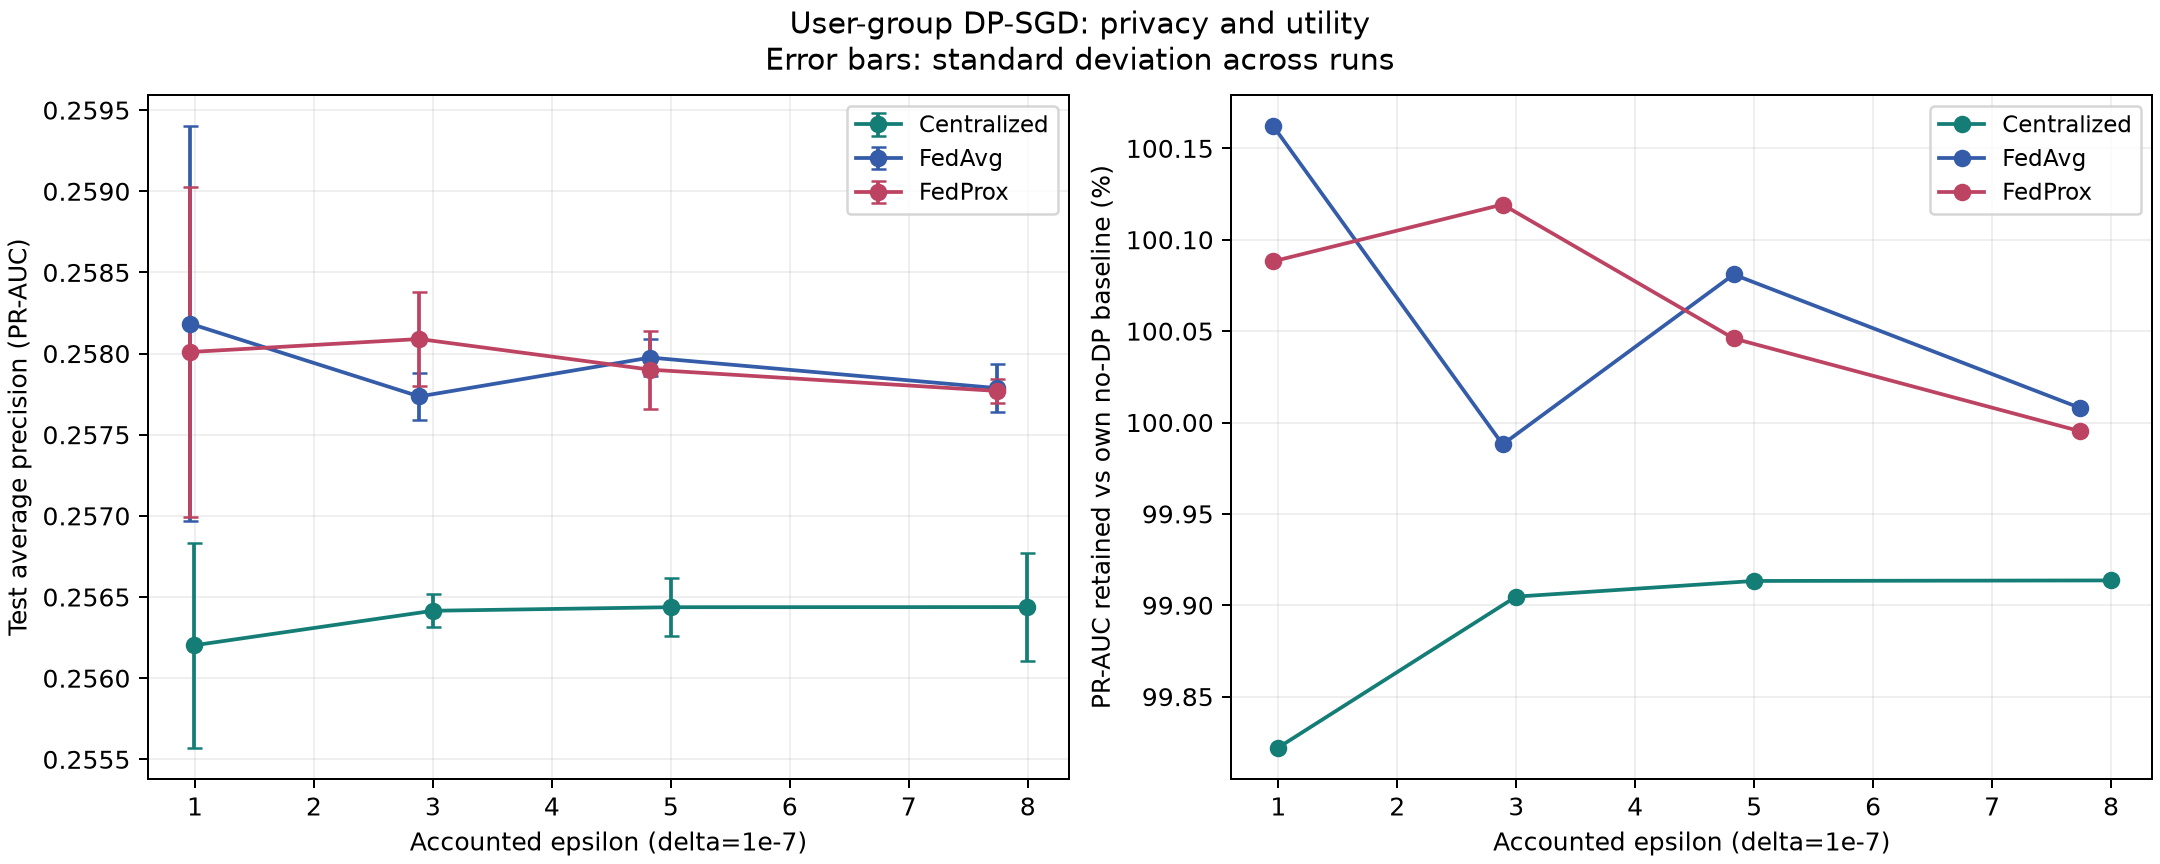

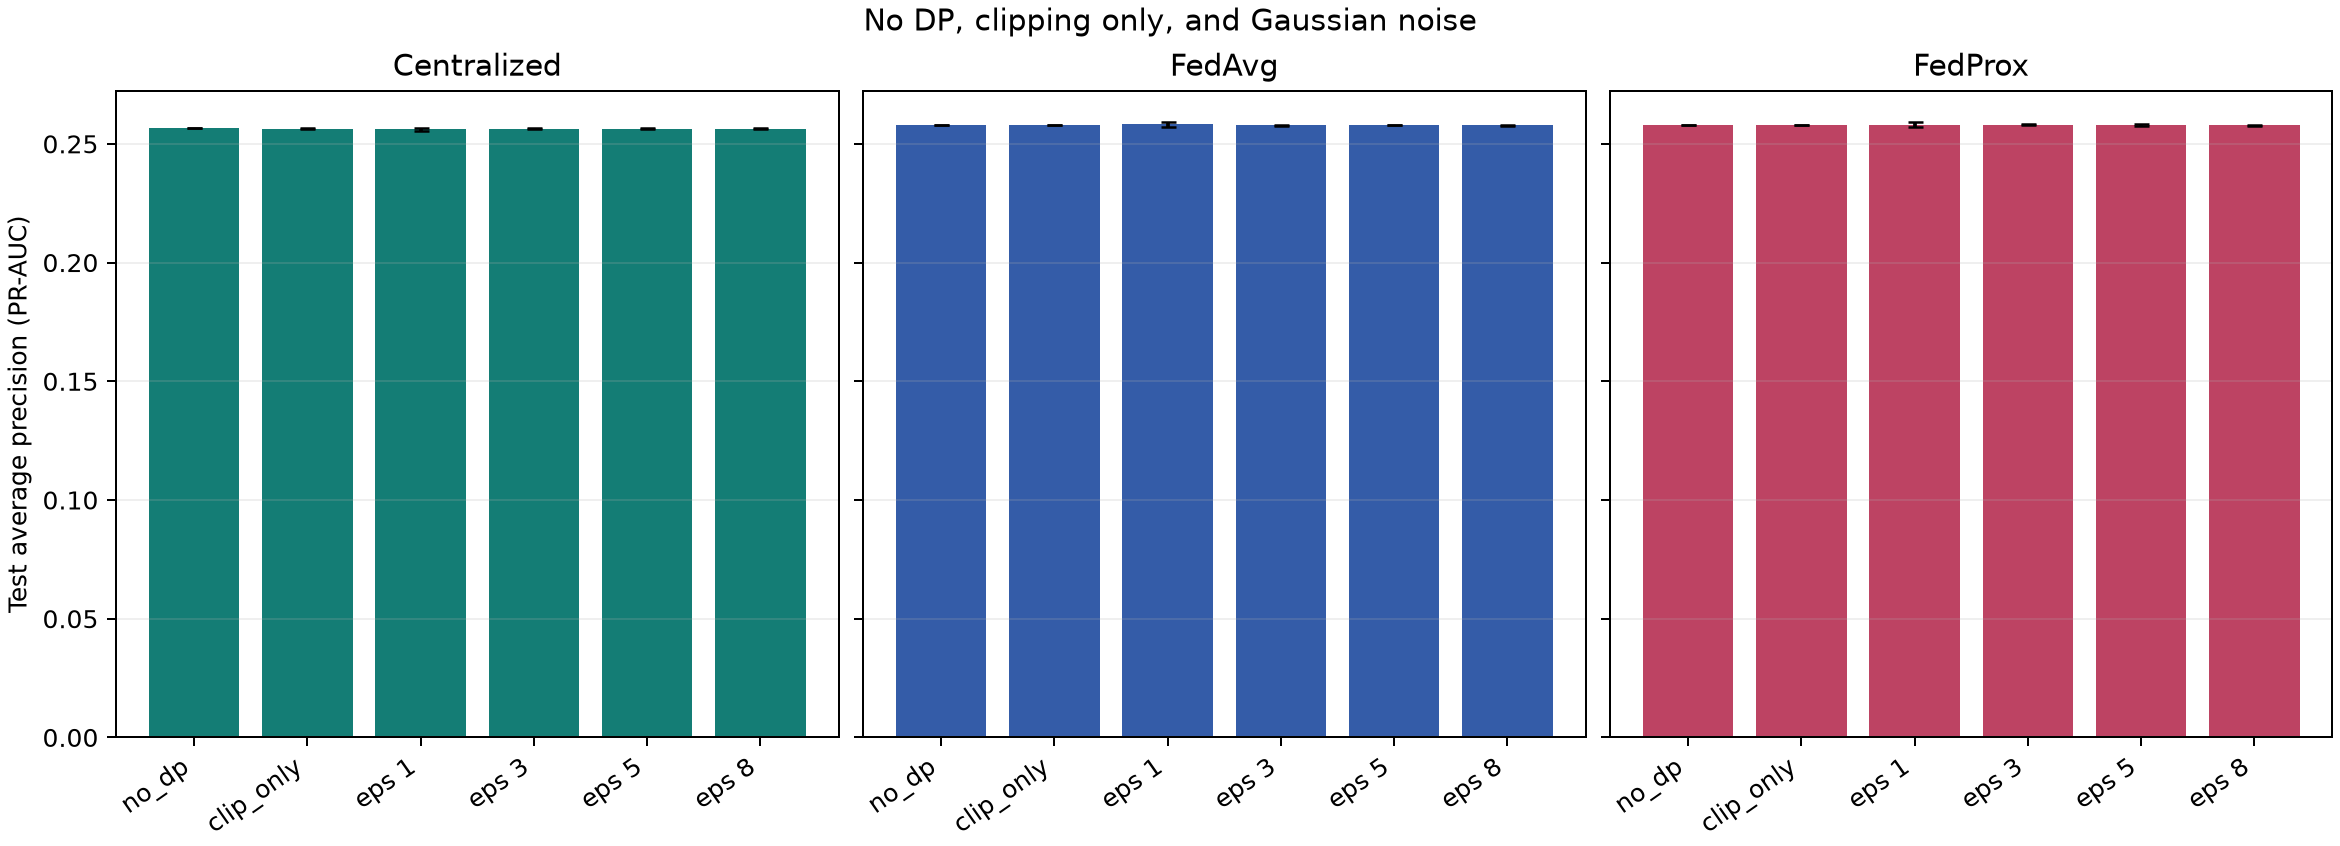

,algorithm,criterion,minimum_retention_pct,status,target_epsilon,epsilon,noise_multiplier,validation_retention_pct
0,Centralized,validation PR-AUC retention,95.0,eligible,1.0,0.995465,1.176758,99.858732
1,FedAvg,validation PR-AUC retention,95.0,eligible,1.0,0.957023,4.160156,100.119494
2,FedProx,validation PR-AUC retention,95.0,eligible,1.0,0.957023,4.160156,100.121654


In [7]:
display(Markdown(report_section(3)))
display(Image(filename=str(RESULTS / 'ml5_privacy_utility.png')))
display(Image(filename=str(RESULTS / 'ml5_noise_comparison.png')))
display(pd.read_csv(RESULTS / 'ml5_privacy_choices.csv'))


## 4.3.6.4. FedProx + DP-SGD

50 client được giữ như ML4. Mỗi client duy trì accountant qua các round; server
tổng hợp theo số người. Proximal term với μ=0.1 được cộng sau gradient đã noised.
FedAvg + DP-SGD là mốc đối chiếu thêm. ε global = max ε_client theo parallel
composition có điều kiện roster công khai, người thuộc một client và weights cố định.


In [8]:
ledger = pd.read_csv(RESULTS / 'ml5_privacy_ledger.csv')
display(Markdown(report_section(4)))



Giữ nguyên 50 client ML4, gộp phiên theo người trong mỗi client, 6
round và 1 lượt lấy mẫu kỳ vọng mỗi round. Tất cả client
tham gia, không giả định khuếch đại riêng tư do chọn client. Server tổng hợp theo số
NGƯỜI của client (khác trọng số session của ML4), coi trọng số và roster là thông tin công khai.
FedProx cộng μ(w_local - w_global) vào gradient sau clipping/noise, gồm cả bias,
với μ = 0.1. Số hạng này không đọc thêm dữ liệu.

Mỗi client có accountant duy trì xuyên suốt các round, không reset ngân sách mỗi round.
Với roster cố định và client rời nhau, ε mỗi mô hình là max ε_client; lịch thực tế từng
client nằm trong `ml5_privacy_ledger.csv`. Đã chạy thêm FedAvg + DP-SGD để đối chiếu
vai trò proximal. Các phép paired t-test theo nhãn lần chạy và Spearman chỉ là thăm dò
với số lần lặp ít, không đủ để khẳng định ưu thế thống kê chắc chắn.

Baseline trong ML5 được chạy lại cùng biến đổi, hàm loss theo người và lịch huấn luyện.
Không đối chiếu trực tiếp số ML4 để gán mọi chênh lệch cho DP vì ML4 dùng scaler,
loss và lịch tối ưu khác.

Bảng kết quả riêng của FedProx + DP-SGD và mốc FedAvg + DP-SGD cùng ε mục tiêu:

| ε mục tiêu | ε thực tế tối đa | FedProx PR-AUC val (TB ± SD) | FedAvg PR-AUC test (TB ± SD) | FedProx PR-AUC test (TB ± SD) | Δ PR-AUC (Prox − Avg) | p thăm dò |
| --- | --- | --- | --- | --- | --- | --- |
| 1.0000 | 0.9570 | 0.254635 ± 0.000846 | 0.258185 ± 0.001217 | 0.258009 ± 0.001019 | -0.000175 | 0.897752 |
| 3.0000 | 2.8856 | 0.254561 ± 0.000220 | 0.257736 ± 0.000146 | 0.258090 ± 0.000289 | +0.000354 | 0.052626 |
| 5.0000 | 4.8275 | 0.254463 ± 0.000266 | 0.257975 ± 0.000113 | 0.257901 ± 0.000240 | -0.000075 | 0.416806 |
| 8.0000 | 7.7415 | 0.254360 ± 0.000056 | 0.257787 ± 0.000148 | 0.257770 ± 0.000073 | -0.000017 | 0.889492 |

Ở ε mục tiêu 1, FedProx + DP-SGD có ε tối đa thực tế
0.9570, PR-AUC test = 0.258009 ± 0.001019 và giữ
100.0882% PR-AUC của baseline FedProx không DP.
Chi tiết chất lượng dự đoán tại cấu hình này:

| Chỉ số | Validation (TB ± SD) | Test (TB ± SD) |
| --- | --- | --- |
| ROC-AUC | 0.947758 ± 0.000012 | 0.943247 ± 0.000019 |
| PR-AUC | 0.254635 ± 0.000846 | 0.258009 ± 0.001019 |
| Balanced Accuracy | 0.931895 ± 0.000000 | 0.928462 ± 0.000000 |
| Precision | 0.268175 ± 0.000000 | 0.263158 ± 0.000000 |
| Recall | 0.882863 ± 0.000000 | 0.874704 ± 0.000000 |
| F1 | 0.411388 ± 0.000000 | 0.404593 ± 0.000000 |
| Accuracy | 0.980156 ± 0.000000 | 0.981445 ± 0.000000 |

Ngân sách và lịch thực tế của các client (min/max trên các client đã ghi):

| ε mục tiêu | ε client nhỏ nhất | ε client lớn nhất | q nhỏ nhất | q lớn nhất | Bước nhỏ nhất | Bước lớn nhất |
| --- | --- | --- | --- | --- | --- | --- |
| 1.0000 | 0.9117 | 0.9570 | 0.0833 | 0.0909 | 66.0000 | 72.0000 |
| 3.0000 | 2.7415 | 2.8856 | 0.0833 | 0.0909 | 66.0000 | 72.0000 |
| 5.0000 | 4.5945 | 4.8275 | 0.0833 | 0.0909 | 66.0000 | 72.0000 |
| 8.0000 | 7.4021 | 7.7415 | 0.0833 | 0.0909 | 66.0000 | 72.0000 |

Hiệu số PR-AUC trung bình **FedProx − FedAvg** trên các mức thử nằm trong
[-0.000175, +0.000354]. Dấu hiệu số thay đổi theo mức ε, nên chưa
quan sát được ưu thế nhất quán của proximal term. p trong bảng là kiểm tra thăm dò
ghép theo nhãn lần chạy với rất ít cặp, không chứng minh hai mô hình tương đương
hay phương pháp nào luôn vượt trội. ε trong bảng cũng chỉ mô tả cơ chế huấn luyện
dưới giả định roster/lấy mẫu đã nêu.



## 4.3.6.5. Trả lời câu hỏi RQ5

Đoạn dưới lấy từ báo cáo được tạo tự động bằng kết quả lần chạy này. Không giả định
FedProx luôn tốt hơn, hoặc chất lượng phải đơn điệu với ε trong thí nghiệm hữu hạn.


In [9]:
report = (RESULTS / 'ML5_Privacy_Utility_Report.md').read_text(encoding='utf-8')
rq5 = report.split('## 4.3.6.5. Trả lời câu hỏi RQ5', 1)[1]
display(Markdown(rq5))
print('Ngân sách compose của tất cả mô hình DP, dưới giả định cơ chế:',
      summary['joint_dp_models_accounted_epsilon'])
print('Cả gói chứa baseline/metrics chưa DP: KHÔNG có bảo đảm DP hữu hạn.')




RQ5 trong báo cáo: “Việc áp dụng DP-SGD ở các mức độ bảo vệ quyền riêng tư khác nhau
ảnh hưởng như thế nào đến hiệu quả mô hình? Khi kết hợp cơ chế bảo vệ quyền riêng tư
với FedProx, sự cân bằng giữa mức độ bảo vệ dữ liệu và chất lượng mô hình thay đổi ra sao?”

Trong lần thực nghiệm này, tăng mức bảo vệ bằng cách giảm ε cần noise multiplier lớn hơn với lịch huấn luyện giữ cố định. Chất lượng dự đoán được đo trực tiếp trong bảng trên; không giả định đường cong phải giảm đơn điệu ở từng lần chạy. Chênh lệch PR-AUC trung bình của FedProx + DP-SGD so với FedAvg + DP-SGD nằm trong [-0.0002, +0.0004] trên các mức ε đã chạy. FedProx không mặc nhiên bù được chi phí nhiễu. Kết luận này chỉ áp dụng cho mô hình Logistic Regression dự đoán purchase theo session, 50 client hash và cấu hình hiện tại; không suy rộng sang chất lượng gợi ý SASRec/HSTU.

Độ thay đổi PR-AUC tuyệt đối lớn nhất giữa một cấu hình DP và baseline không DP
cùng thuật toán là 0.0005. Thí nghiệm có nhiều người và mô hình chỉ
có tám tham số; đây là các yếu tố có thể giúp ảnh hưởng nhiễu nhỏ. Đây là diễn giải
cấu hình, chưa phải bằng chứng nhân quả hay kết luận DP luôn ít ảnh hưởng.
F1 tại ngưỡng 0.5 có thể trùng nhau khi các điểm dự đoán thay đổi nhưng chưa đổi
nhãn phân loại. Các mức ε hiện tại không đủ để khẳng định có một điểm gập rõ ràng.

Ví dụ lựa chọn có điều kiện: yêu cầu giữ ít nhất 95% PR-AUC trên VALIDATION so với
baseline cùng thuật toán, rồi lấy ε mục tiêu nhỏ nhất trong lưới đáp ứng tiêu chí.
Ngưỡng 95% là giả định minh họa, không tối ưu bằng test hay một yêu cầu triển khai đã xác nhận.

| algorithm | criterion | minimum_retention_pct | status | target_epsilon | epsilon | noise_multiplier | validation_retention_pct |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Centralized | validation PR-AUC retention | 95.0000 | eligible | 1.0000 | 0.9955 | 1.1768 | 99.8587 |
| FedAvg | validation PR-AUC retention | 95.0000 | eligible | 1.0000 | 0.9570 | 4.1602 | 100.1195 |
| FedProx | validation PR-AUC retention | 95.0000 | eligible | 1.0000 | 0.9570 | 4.1602 | 100.1217 |

Theo tiêu chí minh họa giữ 95% PR-AUC validation, kết quả lựa chọn là Centralized: ε mục tiêu 1; FedAvg: ε mục tiêu 1; FedProx: ε mục tiêu 1.
Đây là lựa chọn có điều kiện trong
lưới thí nghiệm, chưa xác định ε tối ưu cho triển khai và chưa chứng minh có điểm gập.

Ngân sách RDP cộng dồn của TẤT CẢ mô hình DP trong lần chạy được lưu là
ε = 24.8410, δ = 1e-07.
Giá trị này khác ngân sách từng mô hình ở bảng ε–σ. Nó vẫn chỉ áp dụng cho các cơ
chế mô hình DP theo giả định, không bao gồm việc công bố baseline và metric chưa DP.

### Phạm vi riêng tư phải ghi trong báo cáo

Code đã triển khai gộp và cắt gradient theo người. Tuy nhiên ε trong bảng là ngân sách
của CƠ CHẾ HUẤN LUYỆN theo giả định lấy mẫu/ngẫu nhiên, không chứng nhận toàn bộ
pipeline đạt user-level DP. Adjacency dùng một slot người dùng trong roster công khai:
thêm/bớt toàn bộ đóng góp train của người đó, giữ slot, q, lịch và trọng số cố định.
Không diễn giải như xóa một người rồi tính lại roster, scaler, client size và weights.

Tiền xử lý dữ liệu gốc, visitor/client IDs, kích thước client và mọi metric trên
validation/test không được privatize. Một người có thể xuất hiện ở nhiều split;
bảo vệ các phiên train không bảo vệ việc công bố thống kê từ các phiên test của họ.
Roster benchmark được trích từ train và giả định công khai. Tùy chọn `--public-roster`
nhận roster bên ngoài, giữ người không có phiên ở slot gradient bằng 0. Kiểm tra
số học xác nhận N/q không đổi khi bỏ đóng góp một người trong roster cố định.
Cutoff quan sát của dataset dùng thời điểm giao dịch đầu tiên của phiên positive,
và cuối phiên negative. Đây là thiết lập retrospective phụ thuộc cách xây nhãn;
dự đoán online ở cùng thời điểm cần thiết kế horizon/cutoff chung rồi đánh giá lại.
RNG mặc định là PRNG chưa kiểm toán CSPRNG/khả năng tấn công số thực. Chế độ
deterministic công khai seed chỉ phục vụ tái lập học thuật, không dùng để phát hành DP.
Trước khi tuyên bố bảo vệ user-level toàn hệ thống phải kiểm toán adjacency, sampler,
RNG, tiền xử lý, metrics và tất cả lần phát hành. Nếu phát hành nhiều mô hình trên
cùng người phải cộng ngân sách; CSV mean/std không biến nhiều lần chạy thành một lần.
JSON kèm ngân sách compose chỉ của các mô hình DP, riêng các baseline không DP và
metric không privatize làm cả gói kết quả không có đảm bảo DP hữu hạn.

### Nguồn phương pháp

- [Abadi et al., Deep Learning with Differential Privacy](https://arxiv.org/abs/1607.00133)
- [Opacus DPOptimizer: clipping, Gaussian, expected batch](https://opacus.ai/api/optim/dp_optimizer.html)
- [Opacus RDPAccountant](https://opacus.ai/api/_modules/opacus/accountants/rdp.html)
- [Opacus RNG và secure mode](https://opacus.ai/api/privacy_engine.html)
- [Li et al., FedProx](https://arxiv.org/abs/1812.06127)


Ngân sách compose của tất cả mô hình DP, dưới giả định cơ chế: 24.84099882031358
Cả gói chứa baseline/metrics chưa DP: KHÔNG có bảo đảm DP hữu hạn.


## File kết quả

Bảng CSV, hình PNG, cấu hình JSON và báo cáo Markdown đều ở thư mục `ml5_results`.
Đọc thêm `ML5_README.md` để biết cách chạy nhanh thử luồng và các giả định riêng tư.
Gradient theo người đã có kiểm tra số học, nhưng triển khai thực tế vẫn cần kiểm toán
roster/adjacency, RNG, lấy mẫu, tiền xử lý, metric và tổng ngân sách phát hành.
